# 01 — Exploratory data analysis
**Owner:** Supriye · **Tasks:** S4 step 4 (row counts), S5 step 4 (cleaning report), S7 (EDA items 1–6)

Run top to bottom from the repo's `.venv` after `python -m src.data_loader convert` and `python -m src.labels`. Figures go to `results/figures/`, tables to `results/tables/`.

The *Observation* cells are left empty on purpose: writing them is Supriye's job (TEAM_PLAN Section 12). Values marked PROVISIONAL in `src/config.py` are decided from items 2 and 6.

In [1]:
import sys
from collections import Counter
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.compute as pc
import pyarrow.parquet as pq

from src import data_loader as dl
from src.config import (COMPANY_DOMAIN, FIGURES_DIR, LOGS, PARQUET_DIR, PROCESSED_DIR, RANDOM_STATE,
                        TABLES_DIR, WORK_END_HOUR, WORK_START_HOUR)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160)

def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(FIGURES_DIR / f'{name}.{ext}', dpi=300, bbox_inches='tight')

## S4 step 4 — files, row counts and date ranges
For III. Dataset. `content` was dropped from http and email during conversion.

In [2]:
files = pd.DataFrame(dl.read_manifest()).T[['rows', 'date_min', 'date_max', 'dropped_columns']]
files['rows'] = files['rows'].astype(int)
files.to_csv(TABLES_DIR / 'dataset_files.csv')
files

,rows,date_min,date_max,dropped_columns
file,445581,2010-01-02 07:23:14,2011-05-16 23:22:34,[]
http,28434423,2010-01-02 06:55:16,2011-05-16 21:23:10,[content]
logon,854859,2010-01-02 06:49:00,2011-05-17 06:43:35,[]
email,2629979,2010-01-02 07:11:45,2011-05-16 21:16:26,[content]
device,405380,2010-01-02 07:21:06,2011-05-16 23:22:34,[]


## S5 step 4 — rows removed by cleaning
The loaders drop rows with no date/user and exact duplicates. `http` is too big to de-duplicate in memory, so it is checked through the record `id` (every CERT record has a unique id, so a repeated id = a duplicate row).

In [3]:
for log in ['logon', 'device', 'file', 'email']:
    getattr(dl, f'load_{log}')()
report = dl.cleaning_report()
http = pq.read_table(PARQUET_DIR / 'http.parquet', columns=['id', 'user', 'date'])
n = http.num_rows
no_key = int(pc.sum(pc.or_(pc.is_null(http['user']), pc.is_null(http['date']))).as_py() or 0)
dups = n - pc.count_distinct(http['id']).as_py()
report.loc['http'] = [n, no_key, dups, n - no_key - dups]
del http
report = report.astype(int)
report.to_csv(TABLES_DIR / 'cleaning_report.csv')
report

,rows_in,missing_key_removed,duplicates_removed,rows_out
logon,854859,0,0,854859
device,405380,0,0,405380
file,445581,0,0,445581
email,2629979,0,0,2629979
http,28434423,0,0,28434423


**Observation (Supriye — human-only, TEAM_PLAN 12):** _write 1–2 sentences here._

## S7 item 1 — events per log type per month

,logon,device,file,email,http
date,,,,,
2010-01-01,53857,26101,28844,162649,1765355
2010-02-01,53093,25048,27748,161178,1746095
2010-03-01,60645,28608,31166,184075,1989547
2010-04-01,55110,26121,28432,167445,1815840
2010-05-01,52552,25190,27268,159793,1727506
2010-06-01,56714,27043,29006,172606,1865926
2010-07-01,53832,26244,28208,164958,1781064
2010-08-01,55362,27207,29068,169664,1832661
2010-09-01,52168,25426,27905,160232,1730991


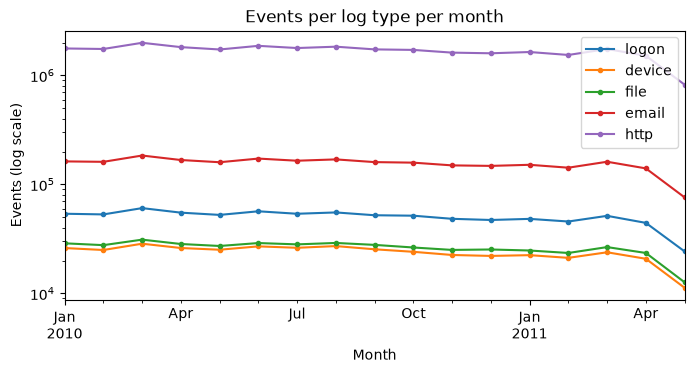

In [4]:
monthly, hourly, weekday = {}, {}, {}
for log in LOGS:
    d = pq.read_table(PARQUET_DIR / f'{log}.parquet', columns=['date'])['date'].to_pandas()
    monthly[log] = d.dt.to_period('M').value_counts().sort_index()
    hourly[log] = d.dt.hour.value_counts().sort_index()
    weekday[log] = d.dt.day_of_week.value_counts().sort_index()
    del d
monthly = pd.DataFrame(monthly).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(8, 3.5))
monthly.index = monthly.index.to_timestamp()
monthly.plot(ax=ax, marker='o', ms=3)
ax.set(yscale='log', xlabel='Month', ylabel='Events (log scale)', title='Events per log type per month')
save(fig, 'eda_events_per_month')
monthly

**Observation (Supriye — human-only, TEAM_PLAN 12):** _write 1–2 sentences here._

## S7 item 2 — activity by hour of day and day of week (all users)
The shaded band is the **PROVISIONAL** working-hours window from `src/config.py`. Supriye decides the real one from this plot (S11, human-only).

,logon,device,file,email,http
date,,,,,
0,0.0050,0.0020,0.0023,0.0000,0.0000
1,0.0053,0.0022,0.0027,0.0000,0.0000
2,0.0052,0.0023,0.0023,0.0000,0.0000
3,0.0053,0.0022,0.0027,0.0000,0.0000
4,0.0054,0.0022,0.0023,0.0000,0.0000
5,0.0060,0.0025,0.0027,0.0000,0.0000
6,0.0079,0.0024,0.0028,0.0003,0.0002
7,0.1751,0.0203,0.0219,0.0331,0.0298
8,0.1659,0.0790,0.0780,0.1047,0.1063


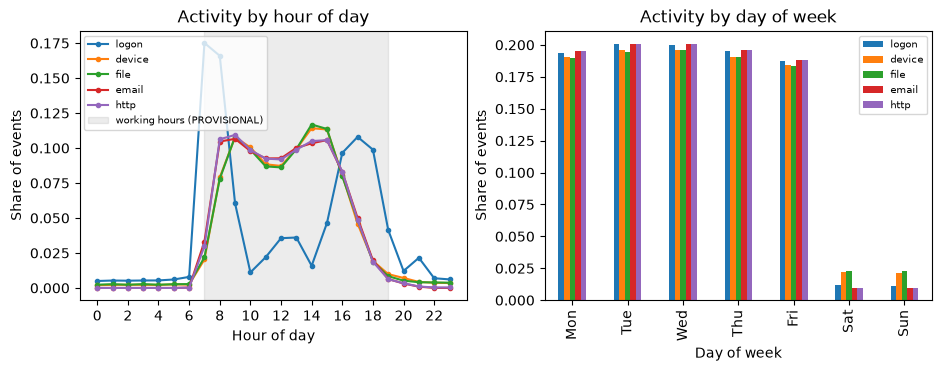

In [5]:
hour_share = pd.DataFrame(hourly).fillna(0)
hour_share = hour_share / hour_share.sum()
day_share = pd.DataFrame(weekday).fillna(0)
day_share = day_share / day_share.sum()
day_share.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
hour_share.plot(ax=a1, marker='o', ms=3)
a1.axvspan(WORK_START_HOUR, WORK_END_HOUR, color='grey', alpha=0.15, label='working hours (PROVISIONAL)')
a1.set(xlabel='Hour of day', ylabel='Share of events', title='Activity by hour of day', xticks=range(0, 24, 2))
a1.legend(fontsize=7)
day_share.plot.bar(ax=a2)
a2.set(xlabel='Day of week', ylabel='Share of events', title='Activity by day of week')
a2.legend(fontsize=7)
save(fig, 'eda_hour_weekday')
hour_share.round(4)

**Observation (Supriye — human-only, TEAM_PLAN 12):** _write 1–2 sentences here._

## S7 item 3 — events per user

,logon,device,file,email,http,total
count,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
mean,855.0,405.0,446.0,2630.0,28434.0,32770.0
std,426.0,1234.0,1462.0,1830.0,20222.0,22552.0
min,58.0,0.0,0.0,34.0,350.0,480.0
25%,692.0,0.0,0.0,1001.0,10034.0,11730.0
50%,692.0,0.0,0.0,3002.0,32870.0,36569.0
75%,968.0,14.0,10.0,3693.0,39444.0,45819.0
max,3470.0,8502.0,11627.0,12034.0,138000.0,150994.0


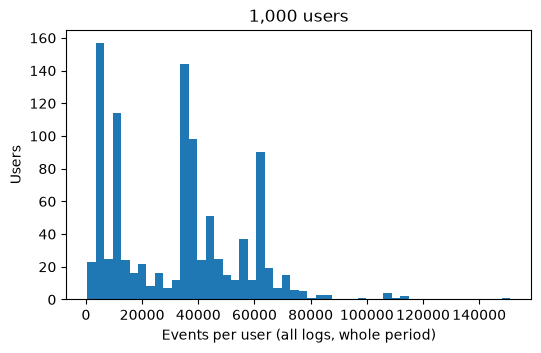

In [6]:
per_user = {}
for log in LOGS:
    counts = pc.value_counts(pq.read_table(PARQUET_DIR / f'{log}.parquet', columns=['user'])['user'])
    per_user[log] = pd.Series(counts.field('counts').to_numpy(), index=counts.field('values').to_pylist())
per_user = pd.DataFrame(per_user).fillna(0).astype(int)
per_user['total'] = per_user.sum(axis=1)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(per_user['total'], bins=50)
ax.set(xlabel='Events per user (all logs, whole period)', ylabel='Users', title=f'{len(per_user):,} users')
save(fig, 'eda_events_per_user')
per_user.describe().round(0)

**Observation (Supriye — human-only, TEAM_PLAN 12):** _write 1–2 sentences here._

## S7 item 4 — class imbalance (table T2)
Rows of the feature table are user-days with at least one logon (S9 step 2), so imbalance is measured on those.

In [7]:
logon = dl.load_logon(columns=['user', 'date', 'activity'])
user_days = logon.loc[logon['activity'] == 'Logon', ['user', 'day']].drop_duplicates()
labels = pd.read_parquet(PROCESSED_DIR / 'labels.parquet')
mal = labels.merge(user_days, on=['user', 'day'])
# insiders = people in answers/insiders.csv; accounts = every account with a malicious day,
# which adds the 2 supervisor accounts hijacked in scenario 3 (open labeling decision, S6)
insiders_csv = dl.load_insiders()
rows = [{'group': 'all', 'insiders': insiders_csv['user'].nunique(),
         'accounts_with_malicious_days': labels['user'].nunique(), 'malicious_user_days': len(mal)}]
for s, g in mal.groupby('scenario'):
    rows.append({'group': f'scenario {s}', 'insiders': (insiders_csv['scenario'] == s).sum(),
                 'accounts_with_malicious_days': labels.loc[labels['scenario'] == s, 'user'].nunique(),
                 'malicious_user_days': len(g)})
imbalance = pd.DataFrame(rows).set_index('group')
imbalance['user_days_total'] = len(user_days)
imbalance['pct_malicious'] = 100 * imbalance['malicious_user_days'] / len(user_days)
imbalance.to_csv(TABLES_DIR / 'class_imbalance.csv')
share = len(mal) / len(user_days)
print(f'{len(user_days):,} user-days with a logon; {len(mal):,} malicious ({100 * share:.3f}%).')
print(f'A model that always says "normal" would score {100 * (1 - share):.2f}% accuracy with 0% recall.')
print(f'Malicious user-days with no logon that day (not in the feature table): {len(labels) - len(mal)}')
imbalance.round(4)

330,268 user-days with a logon; 984 malicious (0.298%).
A model that always says "normal" would score 99.70% accuracy with 0% recall.
Malicious user-days with no logon that day (not in the feature table): 2


,insiders,accounts_with_malicious_days,malicious_user_days,user_days_total,pct_malicious
group,,,,,
all,70,72,984,330268,0.2979
scenario 1,30,30,83,330268,0.0251
scenario 2,30,30,861,330268,0.2607
scenario 3,10,12,40,330268,0.0121


**Observation (Supriye — human-only, TEAM_PLAN 12):** _write 1–2 sentences here._

## S7 item 5 — insider vs. normal user (figure F1)
For each scenario: the insider (from `insiders.csv`) with the most malicious days, next to a randomly chosen normal user with the same role. Daily events across all five logs; malicious days shaded.

,scenario,insider,normal_peer,role
0,1,EHB0824,AOK0844,ProductionLineWorker
1,2,MOS0047,QNP0216,ITAdmin
2,3,BBS0039,LBC0356,ITAdmin


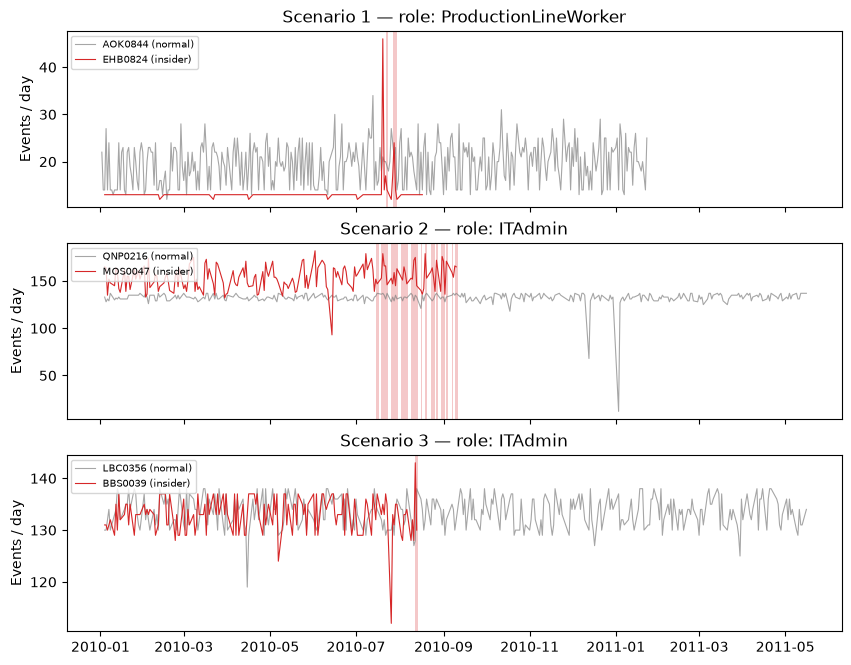

In [8]:
ldap = dl.load_ldap()
insider_users = set(labels['user'])
rng = np.random.default_rng(RANDOM_STATE)
pairs = []
for s in sorted(labels['scenario'].unique()):
    real = set(dl.load_insiders().query('scenario == @s')['user'])  # not the hijacked supervisor accounts
    insider = labels[labels['user'].isin(real)].groupby('user').size().idxmax()
    first = labels.loc[labels['user'] == insider, 'day'].min().to_period('M').to_timestamp()
    # insiders who leave may be missing from that month's snapshot: use their latest record up to it
    own = ldap[(ldap['user_id'] == insider) & (ldap['month'] <= first)].sort_values('month').iloc[-1]
    role = own['role']
    snap = ldap[ldap['month'] == own['month']]
    peers = sorted(set(snap.loc[snap['role'] == role, 'user_id']) - insider_users)
    pairs.append((s, insider, rng.choice(peers), role))
users = [u for _, a, b, _ in pairs for u in (a, b)]
daily = []
for log in LOGS:
    ev = getattr(dl, f'load_{log}')(columns=['user', 'date'], users=users)
    daily.append(ev.groupby(['user', 'day']).size())
daily = pd.concat(daily, axis=1).fillna(0).sum(axis=1).rename('events').reset_index()
fig, axes = plt.subplots(len(pairs), 1, figsize=(10, 2.6 * len(pairs)), sharex=True)
for ax, (s, insider, normal, role) in zip(np.atleast_1d(axes), pairs):
    for user, style in ((normal, dict(color='grey', alpha=0.7)), (insider, dict(color='C3'))):
        d = daily[daily['user'] == user]
        ax.plot(d['day'], d['events'], lw=0.8, label=f"{user} ({'insider' if user == insider else 'normal'})", **style)
    for day in labels.loc[labels['user'] == insider, 'day']:
        ax.axvspan(day, day + pd.Timedelta(days=1), color='C3', alpha=0.25, lw=0)
    ax.set(ylabel='Events / day', title=f'Scenario {s} — role: {role}')
    ax.legend(fontsize=7, loc='upper left')
save(fig, 'F1_insider_vs_normal')
pd.DataFrame(pairs, columns=['scenario', 'insider', 'normal_peer', 'role'])

**Observation (Supriye — human-only, TEAM_PLAN 12):** _write 1–2 sentences here._

## S7 item 6 — top email recipient domains and web domains
Recipient domains confirm the company domain (`COMPANY_DOMAIN` in `src/config.py`, used by S9/S14). The web-domain table is the input for the S15 keyword lists, which Supriye builds by hand (human-only).

In [9]:
email = dl.load_email(columns=['user', 'to', 'cc', 'bcc', 'from'])
domains = dl.recipient_domains(email).explode().value_counts()
top_email = domains.head(50).rename('recipients').to_frame()
top_email.to_csv(TABLES_DIR / 'top50_email_recipient_domains.csv')
own = ldap.drop_duplicates('user_id', keep='last').set_index('user_id')['email'].str.lower()
sender_is_user = (email['from'].str.lower() == email['user'].map(own)).mean()
print(f'COMPANY_DOMAIN in config: {COMPANY_DOMAIN!r}; most common recipient domain: {domains.index[0]!r}')
print(f"Share of emails whose 'from' is the user's own LDAP address: {100 * sender_is_user:.1f}%")
print(f"Share of recipients outside {COMPANY_DOMAIN}: {100 * (1 - domains.get(COMPANY_DOMAIN, 0) / domains.sum()):.1f}%")
top_email.head(15)

COMPANY_DOMAIN in config: 'dtaa.com'; most common recipient domain: 'dtaa.com'
Share of emails whose 'from' is the user's own LDAP address: 62.4%
Share of recipients outside dtaa.com: 41.8%


,recipients
dtaa.com,3547301
netzero.com,174944
gmail.com,173126
yahoo.com,170391
verizon.net,165878
hotmail.com,158843
bellsouth.net,156731
aol.com,152536
optonline.net,152517
comcast.net,149792


In [10]:
web = Counter()
for batch in dl.iter_http_batches(columns=('url',)):
    host = batch['url'].str.extract(r'^https?://([^/:]+)', expand=False).str.lower()
    web.update(host.value_counts().to_dict())
top_web = pd.Series(web, name='visits').sort_values(ascending=False)
print(f'{len(top_web):,} distinct web domains')
top_web.head(100).to_frame().to_csv(TABLES_DIR / 'top100_web_domains.csv')
top_web.head(100).to_frame()

475 distinct web domains


,visits
nfl.com,619672
linkedin.com,472229
vistaprint.com,428795
theblaze.com,424119
eonline.com,371821
...,...
optmd.com,83728
statcounter.com,83374
aol.com,78835
costco.com,77221


**Observation (Supriye — human-only, TEAM_PLAN 12):** _write 1–2 sentences here._

## Decisions this notebook informs (Supriye)
- **After hours (S11):** set `WORK_START_HOUR` / `WORK_END_HOUR` in `src/config.py` from item 2, write the reason in the feature dictionary.
- **Split dates (S8):** run `python -m src.labels`, check `results/tables/split_check.csv`, set `TRAIN_END` / `VAL_END`, copy them into TEAM_PLAN 5.3.
- **Web keyword lists (S15):** build the `job` / `leak` / `cloud` / `hack` lists from `results/tables/top100_web_domains.csv`.
- **Company domain (S14):** confirmed by the recipient-domain table above.

After changing a PROVISIONAL value, re-run `python -m src.features v0` and this notebook.